# Supermarket Sales — Practice

1,000 transactions from 3 branches in Myanmar (Jan–Mar 2019). 17 columns, no nulls, no duplicates.

**Quirks to know:**
- `Date` and `Time` are strings — convert them yourself.
- `Tax 5%` and `gross income` are identical columns.
- `gross margin percentage` is a constant (4.76%) — useless as a feature.
- `Total = cogs + Tax 5%`, and `cogs = Unit price × Quantity`.

Try each exercise yourself before searching for help. Exercises get harder as you go.

In [1]:
# Load the data: 1,000 sales, one row per invoice
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/supermarket_sales.csv")
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


## Level 1 — Cleaning & basics
1. Convert `Date` to datetime. Combine `Date` + `Time` into one `datetime` column.
2. Add `month`, `weekday`, and `hour` columns.
3. Verify the formulas: does `Unit price * Quantity` equal `cogs`? Does `cogs * 1.05` equal `Total`?
4. Drop the redundant columns (which ones, and why?).
5. Rename columns to snake_case (`Unit price` → `unit_price`).

In [2]:
# First look: size, column types and nulls, then basic stats
# (Jupyter only displays the last line, so shape needs print)
print(df.shape)
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Total                    1000 non-null   float64
 10  Date                     1000 non-null   object 
 11  Time                     1000 non-null   object 
 12  Payment                  1000 non-null   object 
 13  cogs                     1000 non-null   float64
 14  gross margin percentage  

,Unit price,Quantity,Tax 5%,Total,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,0.000000,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905,49.650000,10.00000


In [3]:
# Date was text (object); convert it so we can sort and extract parts.
# min/max check: data runs 2019-01-01 to 2019-03-30, so the format is month/day
df["Date"] = pd.to_datetime(df["Date"])

df.info()
df["Date"].min(), df["Date"].max()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Invoice ID               1000 non-null   object        
 1   Branch                   1000 non-null   object        
 2   City                     1000 non-null   object        
 3   Customer type            1000 non-null   object        
 4   Gender                   1000 non-null   object        
 5   Product line             1000 non-null   object        
 6   Unit price               1000 non-null   float64       
 7   Quantity                 1000 non-null   int64         
 8   Tax 5%                   1000 non-null   float64       
 9   Total                    1000 non-null   float64       
 10  Date                     1000 non-null   datetime64[ns]
 11  Time                     1000 non-null   object        
 12  Payment                  1000 non-n

(Timestamp('2019-01-01 00:00:00'), Timestamp('2019-03-30 00:00:00'))

In [6]:
# Month number (1-3). February has the fewest sales, but also only 28 days
df["month"] = df["Date"].dt.month
df["month"].value_counts()

month
1    352
3    345
2    303
Name: count, dtype: int64

In [10]:
# Day name. Mon and Sun appear 12 times in the period, other days 13
df["weekday"] = df["Date"].dt.day_name() 
df["weekday"].value_counts()

weekday
Saturday     164
Tuesday      158
Wednesday    143
Friday       139
Thursday     138
Sunday       133
Monday       125
Name: count, dtype: int64

In [13]:
# Hour of the sale; giving the format avoids a slow, guessing parse.
# The shop trades roughly 10:00-21:00, busiest hour is 19
df["hour"] = pd.to_datetime(df["Time"], format="%H:%M").dt.hour
df["hour"].value_counts().sort_index()

hour
10    101
11     90
12     89
13    103
14     83
15    102
16     77
17     74
18     93
19    113
20     75
Name: count, dtype: int64

In [14]:
# Check the formula cogs = unit price x quantity, first by eye
df["Unit price"] * df["Quantity"]

0      522.83
1       76.40
2      324.31
3      465.76
4      604.17
        ...  
995     40.35
996    973.80
997     31.84
998     65.82
999    618.38
Length: 1000, dtype: float64

In [15]:
# Put our calculation next to the dataset's cogs to compare
check = df[["Unit price", "Quantity", "cogs"]].copy()
check["my_cogs"] = df["Unit price"] * df["Quantity"]
check.head()

,Unit price,Quantity,cogs,my_cogs
0,74.69,7,522.83,522.83
1,15.28,5,76.40,76.40
2,46.33,7,324.31,324.31
3,58.22,8,465.76,465.76
4,86.31,7,604.17,604.17


In [16]:
# Biggest difference over all rows; ~1e-13 is floating-point noise, so they match
(check["my_cogs"] - check["cogs"]).abs().max()

1.1368683772161603e-13

In [17]:
# Total = cogs + 5% tax holds for every row
(df["cogs"] * 1.05 - df["Total"]).abs().max()

1.1368683772161603e-13

In [18]:
# 0.0: gross income is an exact copy of Tax 5%
(df["Tax 5%"]-df["gross income"]).abs().max()

0.0

In [20]:
# Drop the duplicate (gross income) and the constant (gross margin %) columns
df = df.drop(columns=["gross margin percentage", "gross income"])
df.shape

(1000, 18)

In [21]:
df.columns

Index(['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender',
       'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Date',
       'Time', 'Payment', 'cogs', 'Rating', 'month', 'weekday', 'hour'],
      dtype='object')

In [22]:
# Lowercase all column names
df.columns = df.columns.str.lower()
df.columns

Index(['invoice id', 'branch', 'city', 'customer type', 'gender',
       'product line', 'unit price', 'quantity', 'tax 5%', 'total', 'date',
       'time', 'payment', 'cogs', 'rating', 'month', 'weekday', 'hour'],
      dtype='object')

In [24]:
# snake_case: lowercase and spaces -> underscores ('Unit price' -> 'unit_price')
df.columns = df.columns.str.lower().str.replace(" ", "_")
df.columns

Index(['invoice_id', 'branch', 'city', 'customer_type', 'gender',
       'product_line', 'unit_price', 'quantity', 'tax_5%', 'total', 'date',
       'time', 'payment', 'cogs', 'rating', 'month', 'weekday', 'hour'],
      dtype='object')

In [25]:
# '%' is awkward in a column name
df = df.rename(columns={"tax_5%": "tax"})
df.columns

Index(['invoice_id', 'branch', 'city', 'customer_type', 'gender',
       'product_line', 'unit_price', 'quantity', 'tax', 'total', 'date',
       'time', 'payment', 'cogs', 'rating', 'month', 'weekday', 'hour'],
      dtype='object')

**Level 1 findings**
- No missing values or duplicates; `Date` and `Time` needed converting.
- `cogs = unit price × quantity` and `total = cogs × 1.05` hold for every row.
- `gross income` duplicated `Tax 5%` and `gross margin percentage` was constant, so both were dropped.

## Level 2 — Aggregation (groupby)
6. Total revenue per branch/city. Which is highest?
7. Revenue and average quantity per product line, sorted.
8. Most popular payment method in each city.
9. Do members spend more per transaction than normal customers?
10. Average rating per product line — which is lowest?

In [26]:
# Ex 6: revenue per city
df.groupby("city")["total"].sum()

city
Mandalay     106197.6720
Naypyitaw    110568.7065
Yangon       106200.3705
Name: total, dtype: float64

In [27]:
# Same, highest first
df.groupby("city")["total"].sum().sort_values(ascending=False)

city
Naypyitaw    110568.7065
Yangon       106200.3705
Mandalay     106197.6720
Name: total, dtype: float64

In [29]:
df.groupby("city")["total"].mean()    # average money per sale

city
Mandalay     319.872506
Naypyitaw    337.099715
Yangon       312.354031
Name: total, dtype: float64

In [30]:
df.groupby("city")["total"].count()   # how many sales per city

city
Mandalay     332
Naypyitaw    328
Yangon       340
Name: total, dtype: int64

In [31]:
# Count, average sale and revenue together.
# Naypyitaw leads revenue with the fewest sales: its baskets are bigger
df.groupby("city")["total"].agg(["count", "mean", "sum"])

,count,mean,sum
city,,,
Mandalay,332,319.872506,106197.6720
Naypyitaw,328,337.099715,110568.7065
Yangon,340,312.354031,106200.3705


In [32]:
# Ex 7: same breakdown per product line
df.groupby("product_line")["total"].agg(["count", "mean", "sum"])

,count,mean,sum
product_line,,,
Electronic accessories,170,319.632538,54337.5315
Fashion accessories,178,305.089298,54305.8950
Food and beverages,174,322.671517,56144.8440
Health and beauty,152,323.643020,49193.7390
Home and lifestyle,160,336.636956,53861.9130
Sports and travel,166,332.065220,55122.8265


In [37]:
# Sorted by revenue: Food and beverages wins by balancing count and basket size
df.groupby("product_line")["total"].agg(["count", "mean", "sum"]).sort_values(by="sum", ascending=False).round(2)

,count,mean,sum
product_line,,,
Food and beverages,174,322.67,56144.84
Sports and travel,166,332.07,55122.83
Electronic accessories,170,319.63,54337.53
Fashion accessories,178,305.09,54305.90
Home and lifestyle,160,336.64,53861.91
Health and beauty,152,323.64,49193.74


In [38]:
# Sorted by average sale: the order changes, so revenue = count x mean matters
df.groupby("product_line")["total"].agg(["count", "mean", "sum"]).sort_values(by="mean", ascending=False).round(2)

,count,mean,sum
product_line,,,
Home and lifestyle,160,336.64,53861.91
Sports and travel,166,332.07,55122.83
Health and beauty,152,323.64,49193.74
Food and beverages,174,322.67,56144.84
Electronic accessories,170,319.63,54337.53
Fashion accessories,178,305.09,54305.90


In [40]:
# Named aggregation: different calculations on different columns.
# Items per sale are flat (~5-6) across product lines
df.groupby("product_line").agg(
    revenue=("total", "sum"),
    avg_quantity=("quantity", "mean")
).sort_values("revenue", ascending=False).round(2)

,revenue,avg_quantity
product_line,,
Food and beverages,56144.84,5.47
Sports and travel,55122.83,5.54
Electronic accessories,54337.53,5.71
Fashion accessories,54305.90,5.07
Home and lifestyle,53861.91,5.69
Health and beauty,49193.74,5.62


In [45]:
# Ex 8: payment methods overall (Ewallet and Cash almost tied)
df["payment"].value_counts()

payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64

In [46]:
# Payment per city as a grid: unstack moves payment into columns
df.groupby(["city", "payment"]).size().unstack()

payment,Cash,Credit card,Ewallet
city,,,
Mandalay,110,109,113
Naypyitaw,124,98,106
Yangon,110,104,126


In [44]:
# Favourite method per city: Naypyitaw prefers Cash, the others Ewallet
df.groupby(["city", "payment"]).size().unstack().idxmax(axis=1)

city
Mandalay     Ewallet
Naypyitaw       Cash
Yangon       Ewallet
dtype: object

In [47]:
# Ex 9: members spend ~3% more per visit (tested in Level 4)
df.groupby("customer_type")["total"].agg(["count", "mean", "sum"])

,count,mean,sum
customer_type,,,
Member,501,327.791305,164223.444
Normal,499,318.122856,158743.305


In [56]:
# Ex 10: average rating per product line, lowest first
df.groupby("product_line")["rating"].mean().sort_values()

product_line
Home and lifestyle        6.837500
Sports and travel         6.916265
Electronic accessories    6.924706
Health and beauty         7.003289
Fashion accessories       7.029213
Food and beverages        7.113218
Name: rating, dtype: float64

In [57]:
# Average rating per city
df.groupby("city")["rating"].mean().sort_values()

city
Mandalay     6.818072
Yangon       7.027059
Naypyitaw    7.072866
Name: rating, dtype: float64

**Level 2 findings**
- Naypyitaw leads revenue with the fewest sales, thanks to the biggest average basket.
- Food and beverages leads product lines; Health and beauty is last because it has the fewest sales.
- The overall payment tie hides city differences: Naypyitaw prefers Cash, Yangon Ewallet.
- Members spend ~3% more per visit; ratings are similar everywhere (~7).

## Level 3 — Time & pivots
11. Plot daily revenue over the 3 months. Any trend?
12. Which hour of the day has the most sales? Which weekday?
13. Pivot table: rows = product line, columns = gender, values = total revenue.
14. Month-over-month revenue growth (%) per branch.
15. Heatmap of revenue by weekday × hour.

In [58]:
# Ex 11: revenue per day
daily = df.groupby("date")["total"].sum()
daily.head()

date
2019-01-01    4745.1810
2019-01-02    1945.5030
2019-01-03    2078.1285
2019-01-04    1623.6885
2019-01-05    3536.6835
Name: total, dtype: float64

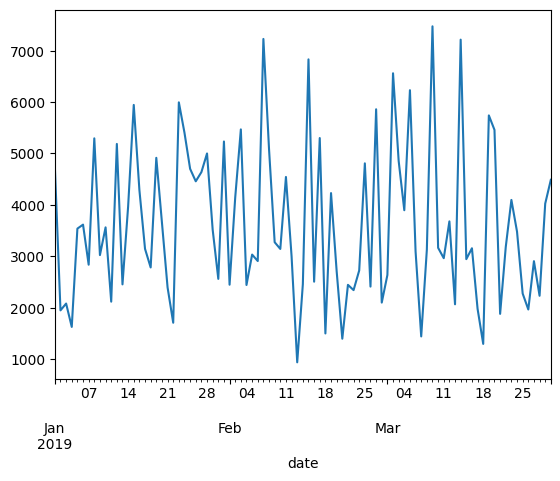

In [60]:
# Raw daily line: too noisy to see a trend
daily.plot();

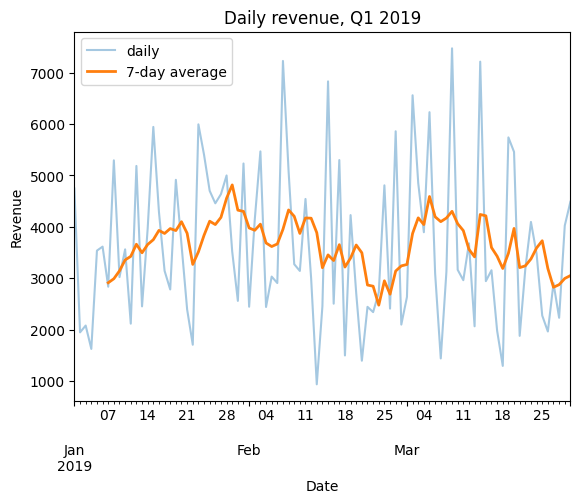

In [62]:
# 7-day rolling average smooths the noise; starts on Jan 7 (needs 7 days).
# Flat over Q1 with a dip in late February
daily.plot(label="daily", alpha=0.4)
daily.rolling(7).mean().plot(label="7-day average", linewidth=2)
plt.title("Daily revenue, Q1 2019")
plt.ylabel("Revenue")
plt.xlabel("Date")
plt.legend();

,count,sum,mean
hour,,,
10,101,31421.0,311.0
11,90,30377.0,338.0
12,89,26066.0,293.0
13,103,34723.0,337.0
14,83,30828.0,371.0
15,102,31180.0,306.0
16,77,25226.0,328.0
17,74,24445.0,330.0
18,93,26030.0,280.0


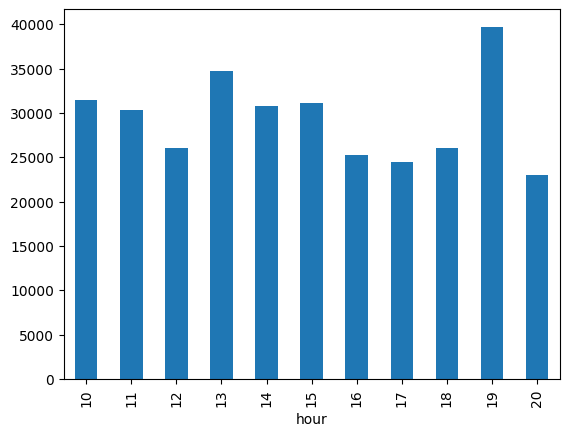

In [64]:
# Ex 12: revenue per hour. The table explains the chart:
# hour 14 has few sales but the highest average sale
hourly = df.groupby("hour")["total"].sum()
hourly.plot(kind="bar");
df.groupby("hour")["total"].agg(["count", "sum", "mean"]).round(0)

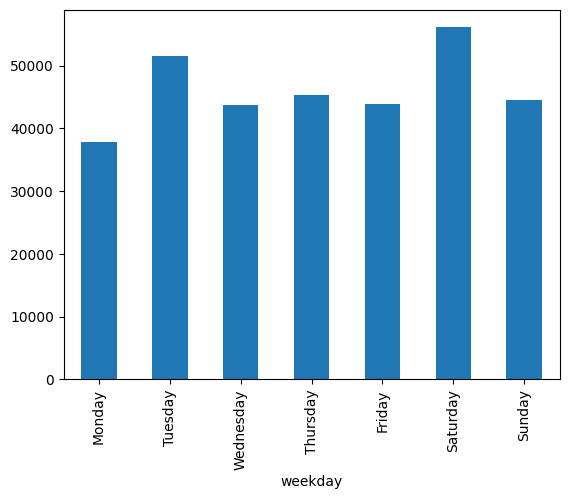

In [66]:
# Revenue per weekday, reordered Monday -> Sunday (default is alphabetical)
weekly = df.groupby("weekday")["total"].sum()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekly.reindex(order).plot(kind="bar");

In [67]:
# How many dates each weekday covers (Mon/Sun: 12, others: 13)
days = df.groupby("weekday")["date"].nunique()
days

weekday
Friday       13
Monday       12
Saturday     13
Sunday       12
Thursday     13
Tuesday      13
Wednesday    13
Name: date, dtype: int64

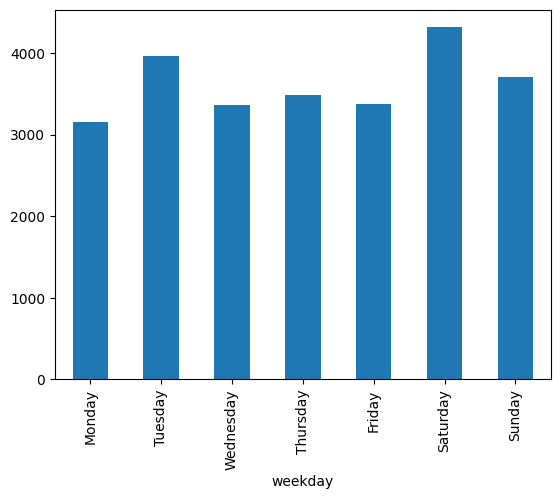

In [68]:
# Fair comparison: average revenue per day.
# Sunday moves up to 3rd; Monday is still the weakest
weekday_per_day = weekly / days
weekday_per_day.reindex(order).plot(kind="bar");

In [71]:
# Ex 13: revenue by product line x gender; diff > 0 means women spent more.
# Men lead Health and beauty, women lead Food and beverages
pivot = pd.pivot_table(df,
                       index="product_line",
                       columns="gender",
                       values="total",
                       aggfunc="sum").round(0)

pivot["diff"] = pivot["Female"] - pivot["Male"]
pivot.sort_values("diff")

gender,Female,Male,diff
product_line,,,
Health and beauty,18561.0,30633.0,-12072.0
Electronic accessories,27102.0,27236.0,-134.0
Sports and travel,28575.0,26548.0,2027.0
Home and lifestyle,30037.0,23825.0,6212.0
Fashion accessories,30437.0,23868.0,6569.0
Food and beverages,33171.0,22974.0,10197.0


In [72]:
# Ex 14: revenue per month (rows) and branch (columns)
monthly = pd.pivot_table(df,
                         index="month",
                         columns="branch",
                         values="total",
                         aggfunc="sum")
monthly

branch,A,B,C
month,,,
1,38681.1285,37176.0585,40434.6810
2,29860.1205,34424.2710,32934.9825
3,37659.1215,34597.3425,37199.0430


In [73]:
# Month-over-month % change; January is NaN (nothing to compare with)
monthly.pct_change() * 100

branch,A,B,C
month,,,
1,NaN,NaN,NaN
2,-22.804423,-7.402042,-18.547688
3,26.118451,0.502760,12.946904


In [74]:
# Same growth per day, since February has only 28 days.
# Branch B actually grew in February; only A and C dipped
days_in_month = [31, 28, 31]
month_per_day = monthly.div(days_in_month, axis=0)
month_per_day.pct_change() * 100

branch,A,B,C
month,,,
1,NaN,NaN,NaN
2,-14.533468,2.519168,-9.820655
3,13.913440,-9.223313,2.016558


In [79]:
# Ex 15: heatmap of revenue by weekday x hour.
# axis=None colours against the whole table, not column by column.
# Peaks: Tuesday and Saturday at 19:00
heat = pd.pivot_table(df,
                      index="weekday",
                      columns="hour",
                      values="total",
                      aggfunc="sum")
heat = heat.reindex(order)
heat.style.background_gradient(cmap="Reds", axis=None).format("{:.0f}")

hour,10,11,12,13,14,15,16,17,18,19,20
weekday,,,,,,,,,,,
Monday,3738,2873,4726,3759,2004,5141,4691,3179,2806,2599,2383
Tuesday,4585,5224,3739,3963,4953,7020,3831,2976,2418,9199,3575
Wednesday,3177,5005,3238,6734,3213,4856,3230,3101,4234,4160,2783
Thursday,6885,4403,2564,2594,5474,4313,4327,4057,3022,3185,4525
Friday,5672,2649,2159,6824,5166,3696,3092,1893,3175,5476,4122
Saturday,3296,5487,4911,5690,5342,3471,3814,5070,6739,9117,3185
Sunday,4067,4737,4728,5160,4676,2682,2241,4169,3637,5964,2397


**Level 3 findings**
- Revenue is flat across Q1; the 7-day average dips in late February and recovers in March.
- Per day, Saturday, Tuesday and Sunday are the strongest days; Monday is the weakest.
- Men drive Health and beauty revenue; women drive Food and beverages.
- After adjusting for February's 28 days, only branches A and C dipped; B grew.
- The 19:00 peak comes mainly from Tuesday and Saturday.

## Level 4 — Interview-style questions
16. Is there a statistically significant difference in `Total` between members and normal customers? (t-test)
17. Is `Rating` correlated with `Total` or `Unit price`? What does that tell you?
18. Is product line choice independent of gender? (chi-square test)
19. Write the same queries as Level 2 in SQL (load the CSV into `sqlite3` with `df.to_sql`).
20. Write a 5-bullet summary for a store manager: what should they do differently?

In [81]:
# Ex 16: split the money column into two groups (== compares, = assigns)
members = df[df["customer_type"] == "Member"]["total"]
normals = df[df["customer_type"] == "Normal"]["total"]
len(members), len(normals)

(501, 499)

In [82]:
# t-test: p = 0.53 (> 0.05), so the members' 3% lead could easily be luck
from scipy import stats

stats.ttest_ind(members, normals)

TtestResult(statistic=0.6215268724928228, pvalue=0.5343949596143621, df=998.0)

In [83]:
# Ex 17: rating vs spend is ~0 (no link).
# total correlates with price and quantity because it is calculated from them
df[["rating", "total", "unit_price", "quantity"]].corr().round(2)

,rating,total,unit_price,quantity
rating,1.00,-0.04,-0.01,-0.02
total,-0.04,1.00,0.63,0.71
unit_price,-0.01,0.63,1.00,0.01
quantity,-0.02,0.71,0.01,1.00


In [84]:
# Ex 18: number of sales per product line x gender
table = pd.crosstab(df["product_line"], df["gender"])
table

gender,Female,Male
product_line,,
Electronic accessories,84,86
Fashion accessories,96,82
Food and beverages,90,84
Health and beauty,64,88
Home and lifestyle,79,81
Sports and travel,88,78


In [85]:
# Chi-square: p = 0.33, so product choice is not significantly linked to gender
stats.chi2_contingency(table)

Chi2ContingencyResult(statistic=5.744455859582644, pvalue=0.3318838580553909, dof=5, expected_freq=array([[85.17 , 84.83 ],
       [89.178, 88.822],
       [87.174, 86.826],
       [76.152, 75.848],
       [80.16 , 79.84 ],
       [83.166, 82.834]]))

In [87]:
# Ex 19: copy df into an in-memory SQLite table called 'sales'
import sqlite3

conn = sqlite3.connect(":memory:")
df.to_sql("sales", conn, index=False, if_exists="replace")

1000

In [88]:
# SQL version of revenue per city (same numbers as Ex 6)
query = """
SELECT city, SUM(total) AS revenue
FROM sales
GROUP BY city
"""
pd.read_sql(query, conn)

,city,revenue
0,Mandalay,106197.6720
1,Naypyitaw,110568.7065
2,Yangon,106200.3705


In [89]:
# SQL version of Ex 7, sorted by revenue
query = """
SELECT product_line,
       COUNT(*)              AS sales,
       ROUND(AVG(total), 2)  AS avg_sale,
       ROUND(SUM(total), 2)  AS revenue
FROM sales
GROUP BY product_line
ORDER BY revenue DESC
"""
pd.read_sql(query, conn)

,product_line,sales,avg_sale,revenue
0,Food and beverages,174,322.67,56144.84
1,Sports and travel,166,332.07,55122.83
2,Electronic accessories,170,319.63,54337.53
3,Fashion accessories,178,305.09,54305.89
4,Home and lifestyle,160,336.64,53861.91
5,Health and beauty,152,323.64,49193.74


In [ ]:
# Same query per city
query = """
SELECT city,
       COUNT(*)              AS sales,
       ROUND(AVG(total), 2)  AS avg_sale,
       ROUND(SUM(total), 2)  AS revenue
FROM sales
GROUP BY city
ORDER BY revenue DESC
"""
pd.read_sql(query, conn)

## Summary for the store manager

1. **Staffing:** The busiest times are Tuesday and Saturday at 7 PM (about 9,000 revenue each), while Monday evenings are quiet. → Add extra cashiers on Tuesday and Saturday evenings; use fewer staff on Monday evenings.
2. **Stock:** Saturday, Tuesday and Sunday bring in the most money per day (Saturday about 4,300/day), and Monday the least (about 3,150/day). → Restock shelves before Saturday and Tuesday.
3. **Branches:** Naypyitaw earns the most (110,569) with the fewest customers, because each spends more (337 per visit). Yangon has the most customers (340) but the smallest baskets (312). → Naypyitaw: advertise to bring in more customers. Yangon: train staff to suggest extra products and try bundle offers.
4. **Loyalty program:** Members spend about 3% more, but a t-test (p = 0.53) shows this could be luck. → Don't invest more in the program yet; test it properly first.
5. **Payments:** Naypyitaw prefers cash (124 sales) and uses cards least (98); Yangon prefers Ewallet (126). → Keep enough cash handling in Naypyitaw and make Ewallet fast and reliable in Yangon.
6. **Health and beauty:** This is the lowest-revenue product line (49,194) because it has the fewest sales (152), not because baskets are small (average 324, about the same as other lines). → Promote it more, for example with better shelf placement or discounts, to bring in more buyers.

**Limitations**
- The data covers only 3 months (Jan–Mar 2019), so seasonal patterns (holidays, summer) can't be seen.
- There is no cost or profit data: "gross income" is just the 5% tax, so this analysis is about revenue, not profit.
- Some differences are small (members vs. normal, ratings) and were not statistically significant, so they should be tested before acting on them.